Размер датасета: (284807, 31)

Распределение классов:
Class
0    284315
1       492
Name: count, dtype: int64
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Лучшие параметры бэггинга:
{'estimator__max_depth': 4, 'max_samples': 0.7, 'n_estimators': 20}
Лучший F1 на кросс-валидации: 0.8386952328247292
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Лучшие параметры бустинга:
{'learning_rate': 0.5, 'n_estimators': 20}
Лучший F1 на кросс-валидации: 0.8897710301394511

===== Bagging =====
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.10      0.85      0.18        98

    accuracy                           0.99     56962
   macro avg       0.55      0.92      0.59     56962
weighted avg       1.00      0.99      0.99     56962

Матрица ошибок:
[[56117   747]
 [   15    83]]

===== AdaBoost =====
              precision    recall  f1-score   support

           0       1.00      1.00

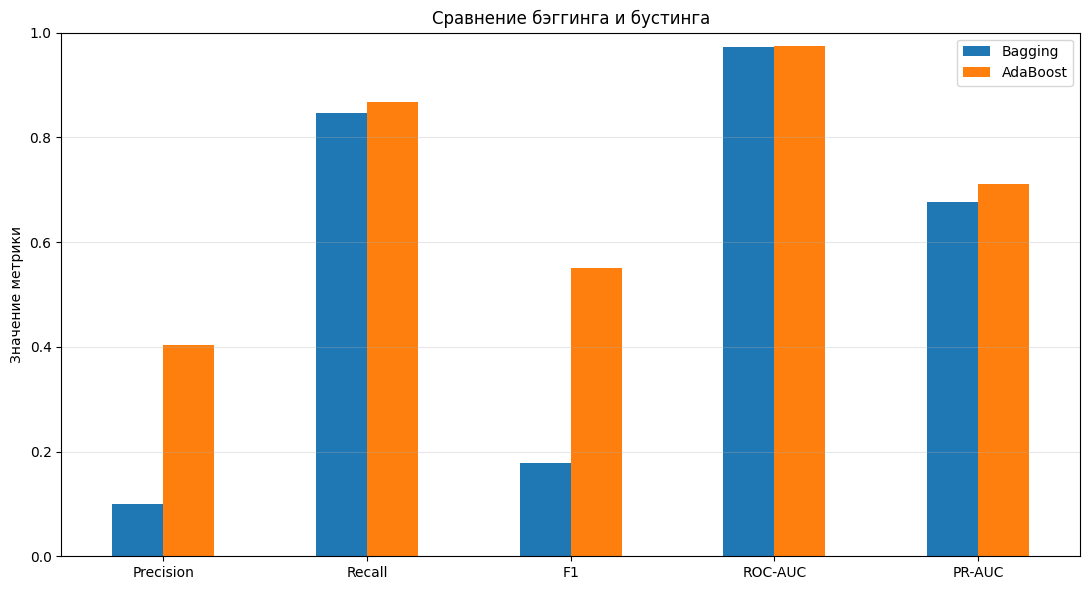


Лучшая модель по F1: AdaBoost
F1-score: 0.5502


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# 1. Загрузка датасета
df = pd.read_csv("./creditcard.csv")

print("Размер датасета:", df.shape)
print("\nРаспределение классов:")
print(df["Class"].value_counts())

# 2. Разделяем признаки и целевую переменную
X = df.drop(columns=["Class"])
y = df["Class"]

# Делим данные на обучение (80%) и тестирование (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Для ускорения GridSearchCV используем часть обучающих данных.
# Сохраняем все мошеннические операции и 10000 обычных.
train_data = X_train.copy()
train_data["Class"] = y_train

fraud = train_data[train_data["Class"] == 1]
normal = train_data[train_data["Class"] == 0].sample(
    n=10000,
    random_state=42
)

train_sample = pd.concat([fraud, normal]).sample(
    frac=1,
    random_state=42
)

X_sample = train_sample.drop(columns=["Class"])
y_sample = train_sample["Class"]

# 3. Бэггинг
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    random_state=42,
    n_jobs=1
)

bagging_params = {
    "n_estimators": [10, 20],
    "max_samples": [0.7, 1.0],
    "estimator__max_depth": [3, 4]
}

bagging_grid = GridSearchCV(
    estimator=bagging,
    param_grid=bagging_params,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

bagging_grid.fit(X_sample, y_sample)

print("\nЛучшие параметры бэггинга:")
print(bagging_grid.best_params_)
print("Лучший F1 на кросс-валидации:",
      bagging_grid.best_score_)

best_bagging = bagging_grid.best_estimator_

# 4. Бустинг
boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    random_state=42
)

boosting_params = {
    "n_estimators": [20, 50],
    "learning_rate": [0.5, 1.0]
}

boosting_grid = GridSearchCV(
    estimator=boosting,
    param_grid=boosting_params,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

boosting_grid.fit(X_sample, y_sample)

print("\nЛучшие параметры бустинга:")
print(boosting_grid.best_params_)
print("Лучший F1 на кросс-валидации:",
      boosting_grid.best_score_)

best_boosting = boosting_grid.best_estimator_

# 5. Сравнение моделей на тестовых данных
models = {
    "Bagging": best_bagging,
    "AdaBoost": best_boosting
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)
    })

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Матрица ошибок:")
    print(confusion_matrix(y_test, y_pred))

# 6. Итоговая таблица
results_df = pd.DataFrame(results)

print("\nИтоговое сравнение моделей:")
print(results_df.to_string(index=False))

# 7. График
results_df.set_index("Модель")[
    ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
].T.plot(kind="bar", figsize=(11, 6))

plt.title("Сравнение бэггинга и бустинга")
plt.ylabel("Значение метрики")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 8. Выбор лучшей модели по F1
best_row = results_df.loc[results_df["F1"].idxmax()]

print("\nЛучшая модель по F1:", best_row["Модель"])
print("F1-score:", round(best_row["F1"], 4))
